In [1]:
import pandas as pd

df = pd.read_csv("df_file.csv")

In [2]:
# Check the number of articles in each label
df["Label"].value_counts()

Label
1    511
4    510
0    417
2    401
3    386
Name: count, dtype: int64

In [3]:
# Check the percentage of each label
df["Label"].value_counts(normalize=True) * 100

Label
1    22.966292
4    22.921348
0    18.741573
2    18.022472
3    17.348315
Name: proportion, dtype: float64

In [7]:
# Count words in each article
df["word_count"] = df["Text"].str.split().str.len()
df[["Text", "word_count"]].head()

,Text,word_count
0,Budget to set scene for election\n \n Gordon B...,538
1,Army chiefs in regiments decision\n \n Militar...,500
2,Howard denies split over ID cards\n \n Michael...,540
3,Observers to monitor UK election\n \n Minister...,496
4,Kilroy names election seat target\n \n Ex-chat...,440


In [5]:
# Get text length statistics
df["word_count"].describe()

count    2225.000000
mean      384.040449
std       238.174497
min        89.000000
25%       246.000000
50%       332.000000
75%       471.000000
max      4432.000000
Name: word_count, dtype: float64

In [8]:
# Compare average word count for each label
df.groupby("Label")["word_count"].mean()

Label
0    453.973621
1    329.262231
2    502.695761
3    330.621762
4    328.880392
Name: word_count, dtype: float64

In [9]:
# Combine all article text
all_text = " ".join(df["Text"])

In [10]:
# Split text into words
words = all_text.lower().split()

In [11]:
# Count word frequency
word_count = {}

for word in words:
    if word in word_count:
        word_count[word] += 1
    else:
        word_count[word] = 1

In [12]:
# Show the 10 most common words
sorted(word_count.items(), key=lambda x: x[1], reverse=True)[:10]

[('the', 51680),
 ('to', 24868),
 ('of', 19919),
 ('and', 18407),
 ('a', 18084),
 ('in', 17358),
 ('for', 8798),
 ('is', 8453),
 ('that', 7711),
 ('on', 7382)]

In [13]:
# Check empty articles
(df["Text"].str.strip() == "").sum()

np.int64(0)

In [14]:
# Check duplicate articles
df["Text"].duplicated().sum()

np.int64(98)

<Axes: xlabel='Label'>

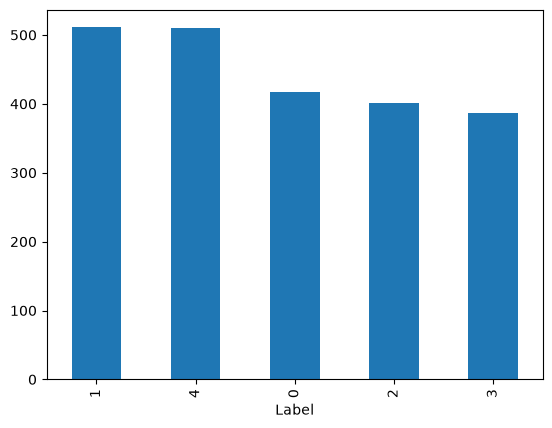

In [15]:
# Plot label distribution
df["Label"].value_counts().plot(kind="bar")

- The dataset contains 2225 articles and 2 columns.
- The dataset has 5 different labels.
- The number of articles in each label is relatively balanced.
- Text length varies between articles.
- Word count helps us understand the length of each article.
- The dataset contains English news articles.